In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from ucimlrepo import fetch_ucirepo

In [2]:
d = fetch_ucirepo(id=350)

X = d.data.features.copy()
y = d.data.targets.iloc[:, 0]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (30000, 23)
y shape: (30000,)


In [3]:
X.columns = (
    ["LIMIT_BAL", "SEX", "EDUCATION", "MARRIAGE", "AGE"]
    + [f"PAY_{i}" for i in (0, 2, 3, 4, 5, 6)]
    + [f"BILL_AMT{i}" for i in range(1, 7)]
    + [f"PAY_AMT{i}" for i in range(1, 7)]
)

print(X.columns.tolist())

['LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE', 'PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6']


In [4]:
df = X.copy()
df["DEFAULT"] = y

print(df.shape)
df.head()

(30000, 24)


,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,DEFAULT
0,20000,2,2,1,24,2,2,-1,-1,-2,...,0,0,0,0,689,0,0,0,0,1
1,120000,2,2,2,26,-1,2,0,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,90000,2,2,2,34,0,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,50000,2,2,1,37,0,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,50000,1,2,1,57,-1,0,-1,0,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


In [5]:
missing = df.isnull().sum()

print(missing[missing > 0])

Series([], dtype: int64)


In [6]:
duplicates = df.duplicated().sum()

print("Duplicate rows:", duplicates)

Duplicate rows: 35


In [7]:
df = df.drop_duplicates().reset_index(drop=True)

print("Shape after removing duplicates:", df.shape)

Shape after removing duplicates: (29965, 24)


In [8]:
print(df["DEFAULT"].value_counts())

DEFAULT
0    23335
1     6630
Name: count, dtype: int64


In [9]:
print(df["DEFAULT"].value_counts(normalize=True) * 100)

DEFAULT
0    77.874187
1    22.125813
Name: proportion, dtype: float64


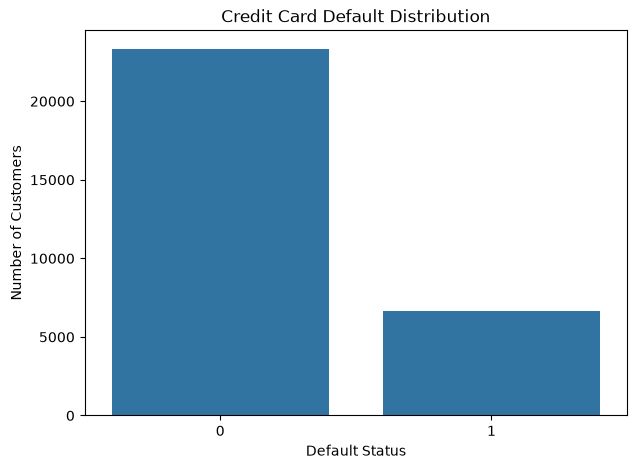

In [10]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="DEFAULT"
)

plt.title("Credit Card Default Distribution")
plt.xlabel("Default Status")
plt.ylabel("Number of Customers")

plt.show()

In [11]:
default_pct = df["DEFAULT"].value_counts(normalize=True) * 100

print(f"Non-default customers: {default_pct[0]:.2f}%")
print(f"Default customers: {default_pct[1]:.2f}%")

Non-default customers: 77.87%
Default customers: 22.13%


In [12]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
LIMIT_BAL,29965.0,167442.005006,129760.135222,10000.0,50000.0,140000.0,240000.0,1000000.0
SEX,29965.0,1.603738,0.489128,1.0,1.0,2.0,2.0,2.0
EDUCATION,29965.0,1.853629,0.790411,0.0,1.0,2.0,2.0,6.0
MARRIAGE,29965.0,1.551877,0.521997,0.0,1.0,2.0,2.0,3.0
AGE,29965.0,35.487969,9.219459,21.0,28.0,34.0,41.0,79.0
PAY_0,29965.0,-0.016753,1.123492,-2.0,-1.0,0.0,0.0,8.0
PAY_2,29965.0,-0.131854,1.196322,-2.0,-1.0,0.0,0.0,8.0
PAY_3,29965.0,-0.164392,1.195878,-2.0,-1.0,0.0,0.0,8.0
PAY_4,29965.0,-0.218922,1.168175,-2.0,-1.0,0.0,0.0,8.0
PAY_5,29965.0,-0.264509,1.132220,-2.0,-1.0,0.0,0.0,8.0


In [13]:
df.head()

,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,DEFAULT
0,20000,2,2,1,24,2,2,-1,-1,-2,...,0,0,0,0,689,0,0,0,0,1
1,120000,2,2,2,26,-1,2,0,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,90000,2,2,2,34,0,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,50000,2,2,1,37,0,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,50000,1,2,1,57,-1,0,-1,0,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


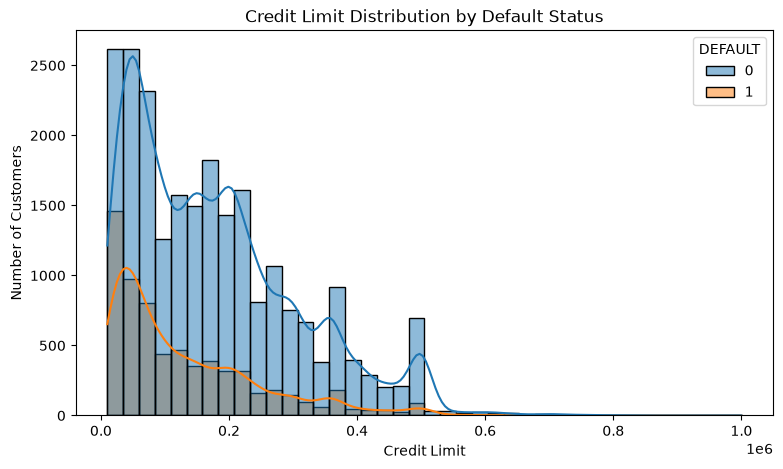

In [14]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="LIMIT_BAL",
    hue="DEFAULT",
    bins=40,
    kde=True
)

plt.title("Credit Limit Distribution by Default Status")
plt.xlabel("Credit Limit")
plt.ylabel("Number of Customers")

plt.show()

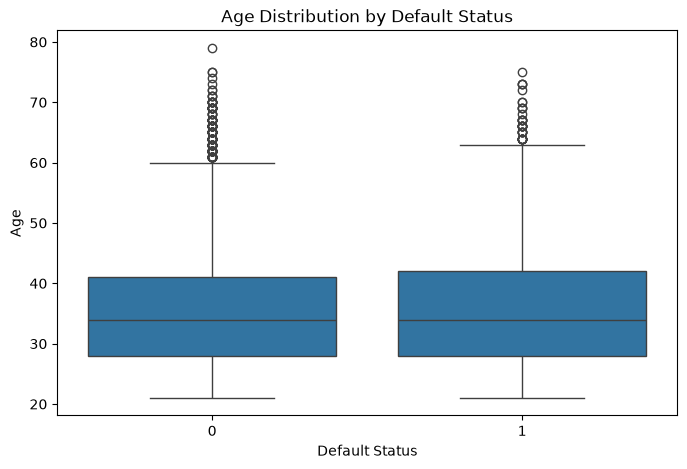

In [15]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="DEFAULT",
    y="AGE"
)

plt.title("Age Distribution by Default Status")
plt.xlabel("Default Status")
plt.ylabel("Age")

plt.show()

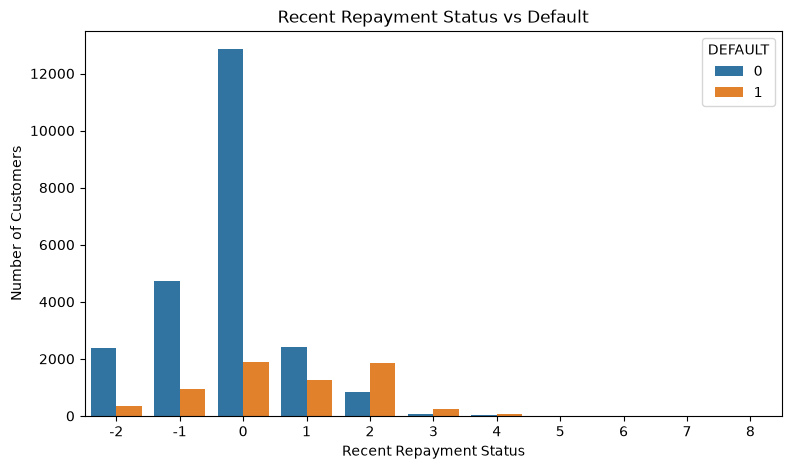

In [16]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="PAY_0",
    hue="DEFAULT"
)

plt.title("Recent Repayment Status vs Default")
plt.xlabel("Recent Repayment Status")
plt.ylabel("Number of Customers")

plt.show()

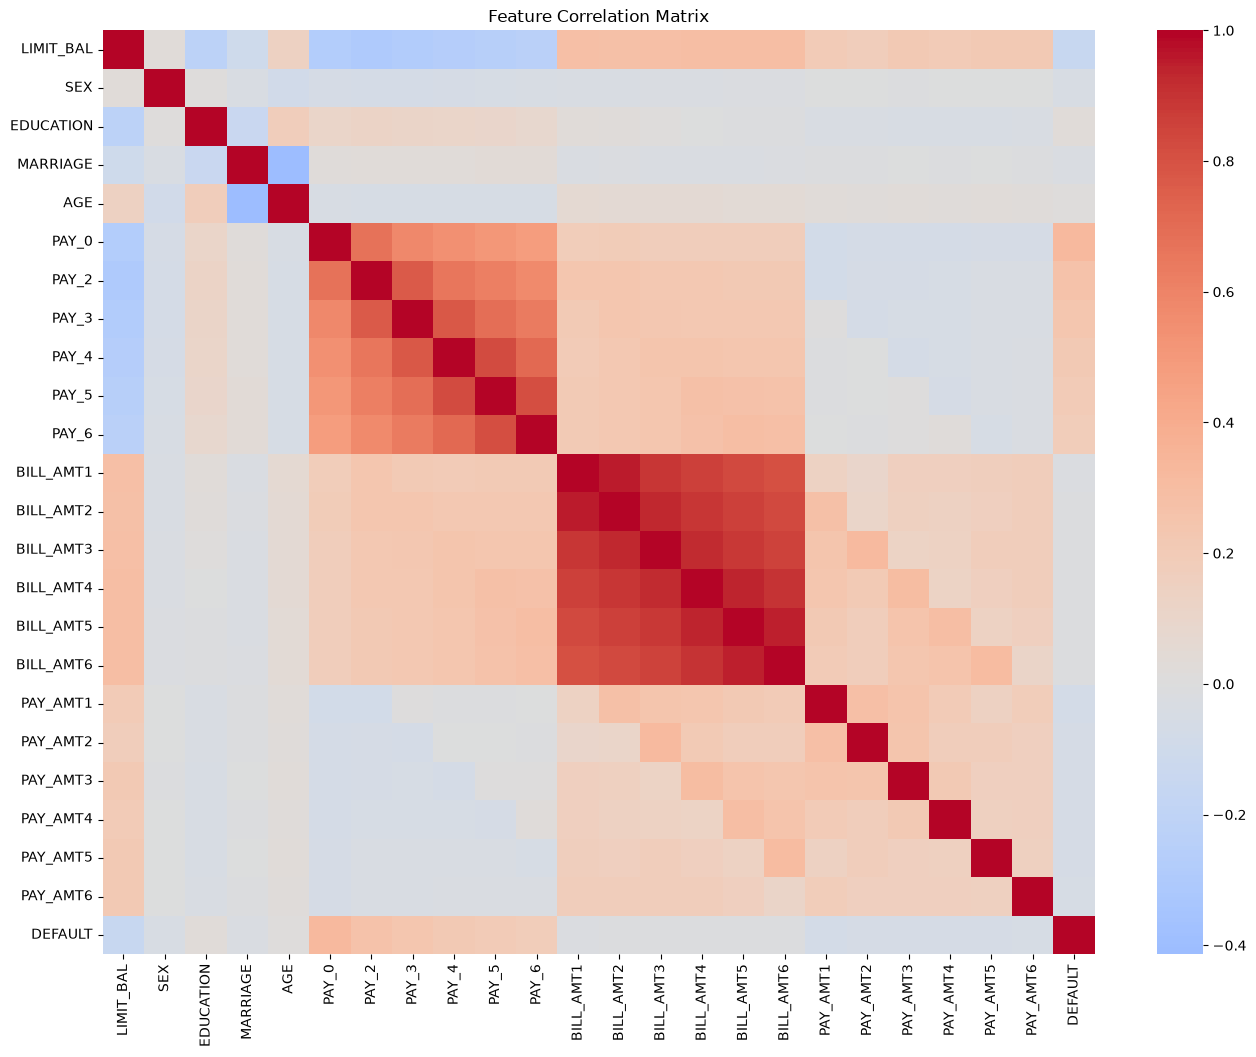

In [17]:
plt.figure(figsize=(16, 12))

correlation = df.corr(numeric_only=True)

sns.heatmap(
    correlation,
    cmap="coolwarm",
    center=0
)

plt.title("Feature Correlation Matrix")

plt.show()

In [18]:
default_corr = (
    df.corr(numeric_only=True)["DEFAULT"]
    .sort_values(ascending=False)
)

print(default_corr)

DEFAULT      1.000000
PAY_0        0.324964
PAY_2        0.263656
PAY_3        0.235230
PAY_4        0.216551
PAY_5        0.204059
PAY_6        0.186740
EDUCATION    0.028017
AGE          0.013619
BILL_AMT6   -0.005469
BILL_AMT5   -0.006859
BILL_AMT4   -0.010259
BILL_AMT3   -0.014182
BILL_AMT2   -0.014302
BILL_AMT1   -0.019758
MARRIAGE    -0.024019
SEX         -0.039742
PAY_AMT6    -0.053250
PAY_AMT5    -0.055194
PAY_AMT3    -0.056319
PAY_AMT4    -0.056898
PAY_AMT2    -0.058643
PAY_AMT1    -0.073015
LIMIT_BAL   -0.153871
Name: DEFAULT, dtype: float64


In [19]:
X = df.drop(columns="DEFAULT")
y = df["DEFAULT"]

In [20]:
X = df.drop(columns="DEFAULT").copy()
y = df["DEFAULT"].copy()

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (29965, 23)
y shape: (29965,)


In [21]:
pay_cols = [
    "PAY_0",
    "PAY_2",
    "PAY_3",
    "PAY_4",
    "PAY_5",
    "PAY_6"
]

X["MAX_DELAY"] = X[pay_cols].max(axis=1)

X["N_LATE"] = (X[pay_cols] > 0).sum(axis=1)

X["AVG_DELAY"] = X[pay_cols].mean(axis=1)

print(X[["MAX_DELAY", "N_LATE", "AVG_DELAY"]].head())

   MAX_DELAY  N_LATE  AVG_DELAY
0          2       2  -0.333333
1          2       2   0.500000
2          0       0   0.000000
3          0       0   0.000000
4          0       0  -0.333333


In [22]:
bill_cols = [
    "BILL_AMT1",
    "BILL_AMT2",
    "BILL_AMT3",
    "BILL_AMT4",
    "BILL_AMT5",
    "BILL_AMT6"
]

payment_cols = [
    "PAY_AMT1",
    "PAY_AMT2",
    "PAY_AMT3",
    "PAY_AMT4",
    "PAY_AMT5",
    "PAY_AMT6"
]

X["AVG_BILL"] = X[bill_cols].mean(axis=1)
X["AVG_PAYMENT"] = X[payment_cols].mean(axis=1)

X["TOTAL_BILL"] = X[bill_cols].sum(axis=1)
X["TOTAL_PAYMENT"] = X[payment_cols].sum(axis=1)

print(
    X[
        [
            "AVG_BILL",
            "AVG_PAYMENT",
            "TOTAL_BILL",
            "TOTAL_PAYMENT"
        ]
    ].head()
)

       AVG_BILL  AVG_PAYMENT  TOTAL_BILL  TOTAL_PAYMENT
0   1284.000000   114.833333        7704            689
1   2846.166667   833.333333       17077           5000
2  16942.166667  1836.333333      101653          11018
3  38555.666667  1398.000000      231334           8388
4  18223.166667  9841.500000      109339          59049


In [23]:
X["UTILIZATION"] = (
    X["BILL_AMT1"].abs() /
    X["LIMIT_BAL"].clip(lower=1)
)

print(X["UTILIZATION"].describe())

count    29965.000000
mean         0.424596
std          0.411107
min          0.000000
25%          0.022606
50%          0.315634
75%          0.830325
max          6.455300
Name: UTILIZATION, dtype: float64


In [24]:
X["PAYMENT_COVERAGE"] = (
    X["PAY_AMT1"] /
    X["BILL_AMT1"].abs().clip(lower=1)
)

print(X["PAYMENT_COVERAGE"].describe())

count     29965.000000
mean        100.341281
std        2700.891183
min           0.000000
25%           0.035305
50%           0.057464
75%           0.294533
max      298887.000000
Name: PAYMENT_COVERAGE, dtype: float64


In [25]:
X["BILL_TREND"] = X["BILL_AMT1"] - X["BILL_AMT6"]

X["PAYMENT_TREND"] = X["PAY_AMT1"] - X["PAY_AMT6"]

print(
    X[
        [
            "BILL_TREND",
            "PAYMENT_TREND"
        ]
    ].head()
)

   BILL_TREND  PAYMENT_TREND
0        3913              0
1        -579          -2000
2       13690          -3482
3       17443           1000
4      -10514           1321


In [26]:
print("Original features:", 23)
print("Final features:", X.shape[1])

print("\nFeature list:")
print(X.columns.tolist())

Original features: 23
Final features: 34

Feature list:
['LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE', 'PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6', 'MAX_DELAY', 'N_LATE', 'AVG_DELAY', 'AVG_BILL', 'AVG_PAYMENT', 'TOTAL_BILL', 'TOTAL_PAYMENT', 'UTILIZATION', 'PAYMENT_COVERAGE', 'BILL_TREND', 'PAYMENT_TREND']


In [27]:
import numpy as np

print("Infinite values:", np.isinf(X).sum().sum())
print("Missing values:", X.isnull().sum().sum())

Infinite values: 0
Missing values: 0


In [28]:
feature_summary = pd.DataFrame({
    "Feature": X.columns,
    "Data Type": X.dtypes.astype(str),
    "Missing Values": X.isnull().sum().values,
    "Unique Values": X.nunique().values
})

feature_summary

,Feature,Data Type,Missing Values,Unique Values
LIMIT_BAL,LIMIT_BAL,int64,0,81
SEX,SEX,int64,0,2
EDUCATION,EDUCATION,int64,0,7
MARRIAGE,MARRIAGE,int64,0,4
AGE,AGE,int64,0,56
PAY_0,PAY_0,int64,0,11
PAY_2,PAY_2,int64,0,11
PAY_3,PAY_3,int64,0,11
PAY_4,PAY_4,int64,0,11
PAY_5,PAY_5,int64,0,10


In [29]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

print("Training set:", X_train.shape)
print("Test set:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTest target distribution:")
print(y_test.value_counts())

Training set: (23972, 34)
Test set: (5993, 34)

Training target distribution:
DEFAULT
0    18668
1     5304
Name: count, dtype: int64

Test target distribution:
DEFAULT
0    4667
1    1326
Name: count, dtype: int64


In [30]:
negative = (y_train == 0).sum()
positive = (y_train == 1).sum()

scale_pos_weight = negative / positive

print("Non-default customers:", negative)
print("Default customers:", positive)
print("Scale Pos Weight:", round(scale_pos_weight, 3))

Non-default customers: 18668
Default customers: 5304
Scale Pos Weight: 3.52


In [31]:
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

In [32]:
models = {
    "Logistic Regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(
            max_iter=1000,
            class_weight="balanced",
            random_state=42
        )
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        class_weight="balanced",
        n_jobs=-1,
        random_state=42
    ),

    "XGBoost": XGBClassifier(
        n_estimators=300,
        max_depth=4,
        learning_rate=0.05,
        scale_pos_weight=scale_pos_weight,
        eval_metric="auc",
        random_state=42,
        n_jobs=-1
    )
}

print(models)

{'Logistic Regression': Pipeline(steps=[('standardscaler', StandardScaler()),
                ('logisticregression',
                 LogisticRegression(class_weight='balanced', max_iter=1000,
                                    random_state=42))]), 'Random Forest': RandomForestClassifier(class_weight='balanced', n_estimators=300, n_jobs=-1,
                       random_state=42), 'XGBoost': XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='auc', feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=0.05, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=4,
              max_leaves=None, min_child_weight=No

In [33]:
for name, model in models.items():
    print(f"Training {name}...")
    model.fit(X_train, y_train)

print("\nAll models trained successfully.")

Training Logistic Regression...
Training Random Forest...
Training XGBoost...

All models trained successfully.


In [34]:
predictions = {}
probabilities = {}

for name, model in models.items():
    predictions[name] = model.predict(X_test)
    probabilities[name] = model.predict_proba(X_test)[:, 1]

print("Predictions generated successfully.")

Predictions generated successfully.


In [35]:
from sklearn.metrics import roc_auc_score

for name in models:
    auc = roc_auc_score(
        y_test,
        probabilities[name]
    )

    print(f"{name}: ROC-AUC = {auc:.4f}")

Logistic Regression: ROC-AUC = 0.7523
Random Forest: ROC-AUC = 0.7640
XGBoost: ROC-AUC = 0.7769


In [36]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    average_precision_score
)

results = []

for name in models:

    y_pred = predictions[name]
    y_prob = probabilities[name]

    results.append({
        "Model": name,
        "ROC-AUC": roc_auc_score(y_test, y_prob),
        "PR-AUC": average_precision_score(y_test, y_prob),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1-Score": f1_score(y_test, y_pred)
    })

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="ROC-AUC",
    ascending=False
)

results_df

,Model,ROC-AUC,PR-AUC,Precision,Recall,F1-Score
2,XGBoost,0.776909,0.553719,0.452575,0.629713,0.526648
1,Random Forest,0.763966,0.527641,0.547538,0.486425,0.515176
0,Logistic Regression,0.752292,0.513651,0.444139,0.608597,0.513522


In [37]:
best_model_name = results_df.iloc[0]["Model"]
best_model = models[best_model_name]

print("Best model based on ROC-AUC:", best_model_name)

Best model based on ROC-AUC: XGBoost


In [38]:
from sklearn.metrics import classification_report

best_predictions = predictions[best_model_name]

print(
    classification_report(
        y_test,
        best_predictions,
        target_names=["Non-Default", "Default"]
    )
)

              precision    recall  f1-score   support

 Non-Default       0.88      0.78      0.83      4667
     Default       0.45      0.63      0.53      1326

    accuracy                           0.75      5993
   macro avg       0.67      0.71      0.68      5993
weighted avg       0.79      0.75      0.76      5993



<Figure size 700x600 with 0 Axes>

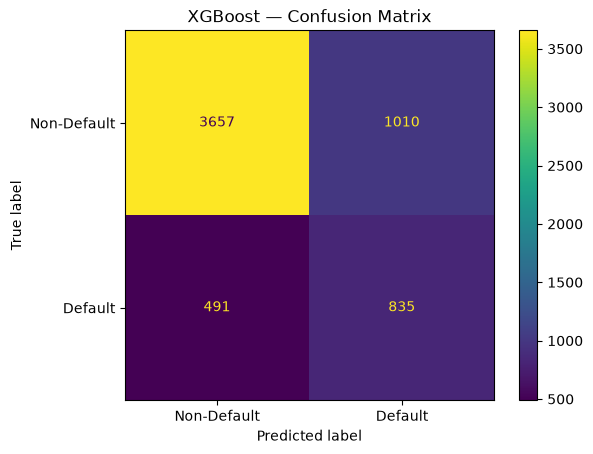

In [39]:
from sklearn.metrics import ConfusionMatrixDisplay

plt.figure(figsize=(7, 6))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    best_predictions,
    display_labels=["Non-Default", "Default"]
)

plt.title(f"{best_model_name} — Confusion Matrix")
plt.show()

<Figure size 900x700 with 0 Axes>

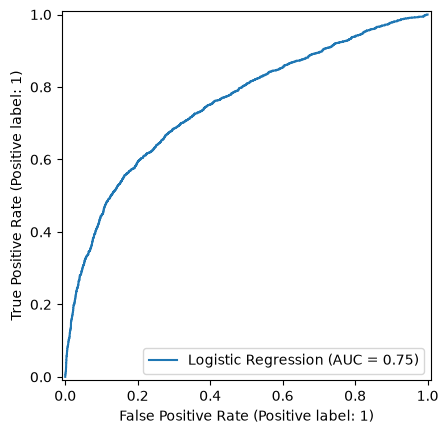

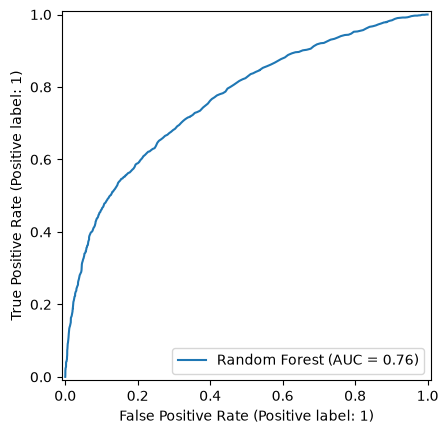

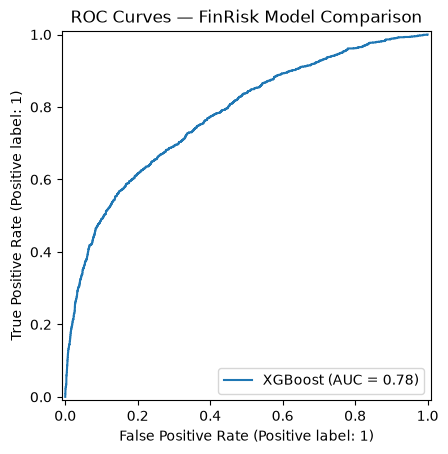

In [40]:
from sklearn.metrics import RocCurveDisplay

plt.figure(figsize=(9, 7))

for name, model in models.items():
    RocCurveDisplay.from_estimator(
        model,
        X_test,
        y_test,
        name=name
    )

plt.title("ROC Curves — FinRisk Model Comparison")
plt.show()

<Figure size 900x700 with 0 Axes>

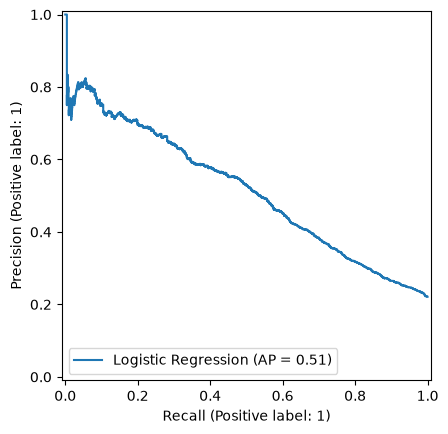

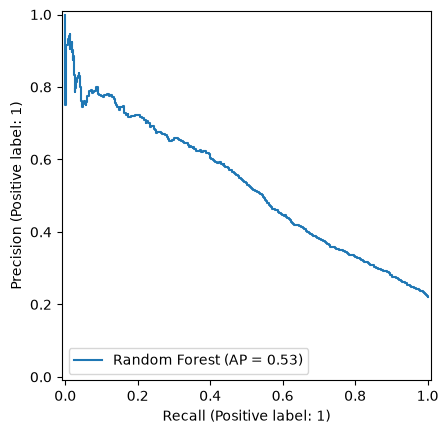

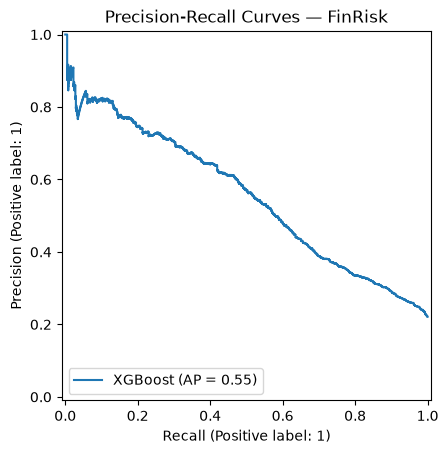

In [41]:
from sklearn.metrics import PrecisionRecallDisplay

plt.figure(figsize=(9, 7))

for name, model in models.items():
    PrecisionRecallDisplay.from_estimator(
        model,
        X_test,
        y_test,
        name=name
    )

plt.title("Precision-Recall Curves — FinRisk")
plt.show()

In [42]:
best_model = models["XGBoost"]

print("Final model:", type(best_model).__name__)

Final model: XGBClassifier


In [43]:
importance = pd.Series(
    best_model.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

print("Top 15 Risk Predictors:")
print(importance.head(15))

Top 15 Risk Predictors:
MAX_DELAY      0.485350
PAY_0          0.102288
N_LATE         0.073115
AVG_BILL       0.030965
PAY_2          0.019940
AVG_PAYMENT    0.019408
UTILIZATION    0.017232
LIMIT_BAL      0.016112
AVG_DELAY      0.015361
PAY_AMT2       0.014490
BILL_AMT2      0.014338
BILL_AMT1      0.012635
PAY_AMT1       0.012100
PAY_AMT4       0.011952
BILL_TREND     0.011251
dtype: float32


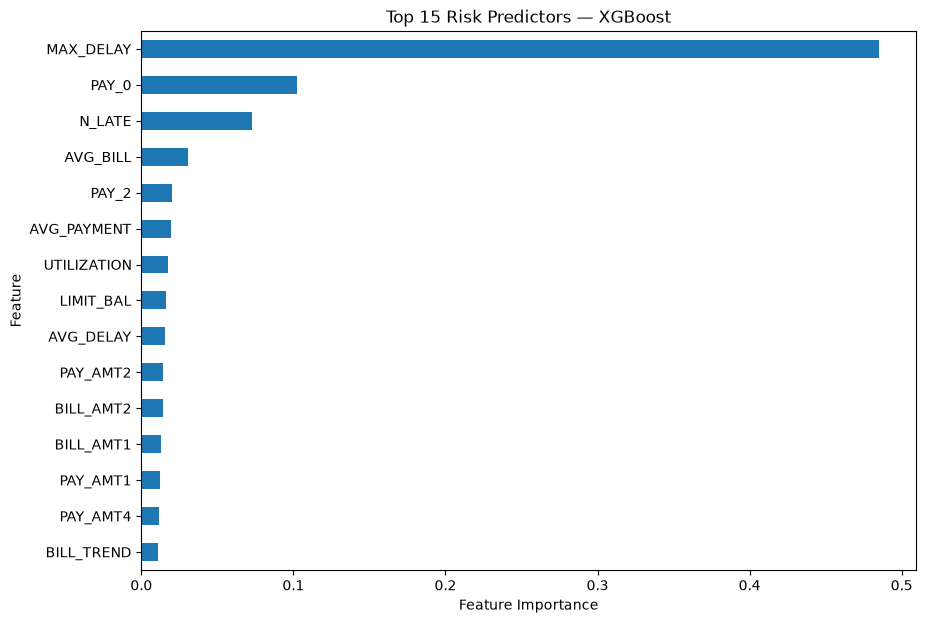

In [44]:
plt.figure(figsize=(10, 7))

importance.head(15).sort_values().plot(
    kind="barh"
)

plt.title("Top 15 Risk Predictors — XGBoost")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")

plt.show()

In [45]:
import shap

explainer = shap.TreeExplainer(best_model)

X_sample = X_test.sample(
    1000,
    random_state=42
)

shap_values = explainer.shap_values(X_sample)

print("SHAP values calculated successfully.")

SHAP values calculated successfully.


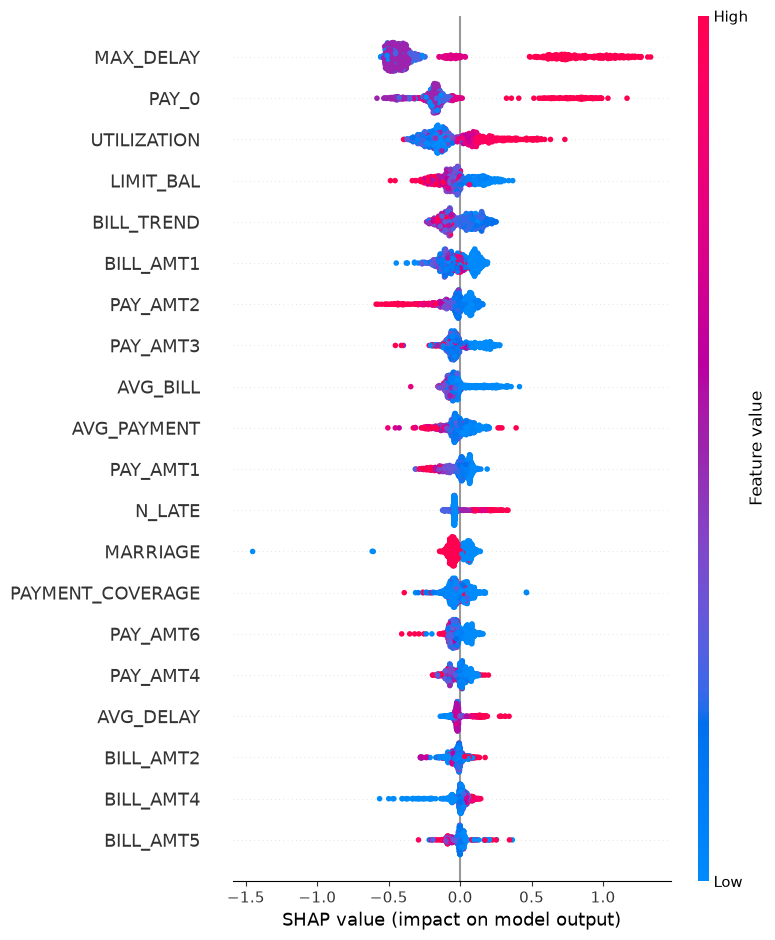

In [46]:
shap.summary_plot(
    shap_values,
    X_sample
)

In [47]:
from sklearn.metrics import precision_score, recall_score, f1_score

y_prob = probabilities["XGBoost"]

thresholds = np.arange(0.20, 0.71, 0.05)

threshold_results = []

for threshold in thresholds:

    y_pred_threshold = (y_prob >= threshold).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_test,
            y_pred_threshold,
            zero_division=0
        ),
        "Recall": recall_score(
            y_test,
            y_pred_threshold,
            zero_division=0
        ),
        "F1": f1_score(
            y_test,
            y_pred_threshold,
            zero_division=0
        )
    })

threshold_df = pd.DataFrame(threshold_results)

threshold_df

,Threshold,Precision,Recall,F1
0,0.20,0.264314,0.943439,0.412939
1,0.25,0.287362,0.901961,0.435860
2,0.30,0.311610,0.858220,0.457212
3,0.35,0.337496,0.794872,0.473814
4,0.40,0.372888,0.732278,0.494148
5,0.45,0.410291,0.679487,0.511641
6,0.50,0.452575,0.629713,0.526648
7,0.55,0.497761,0.586727,0.538595
8,0.60,0.536677,0.540724,0.538693
9,0.65,0.582960,0.490196,0.532569


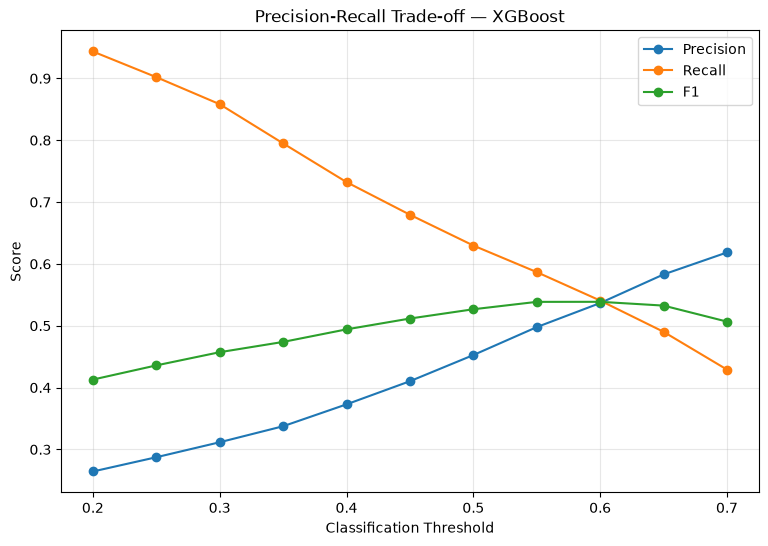

In [48]:
plt.figure(figsize=(9, 6))

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Recall"],
    marker="o",
    label="Recall"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["F1"],
    marker="o",
    label="F1"
)

plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.title("Precision-Recall Trade-off — XGBoost")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [49]:
best_threshold_row = threshold_df.loc[
    threshold_df["F1"].idxmax()
]

print("Best threshold based on F1:")
print(best_threshold_row)

Best threshold based on F1:
Threshold    0.600000
Precision    0.536677
Recall       0.540724
F1           0.538693
Name: 8, dtype: float64


In [50]:
def risk_category(probability):

    if probability < 0.30:
        return "Low Risk"

    elif probability < 0.60:
        return "Medium Risk"

    else:
        return "High Risk"

In [51]:
test_probabilities = [0.10, 0.42, 0.75]

for p in test_probabilities:
    print(
        f"Probability: {p:.0%} → {risk_category(p)}"
    )

Probability: 10% → Low Risk
Probability: 42% → Medium Risk
Probability: 75% → High Risk


In [52]:
risk_output = X_test.copy()

risk_output["Actual_Default"] = y_test.values

risk_output["Default_Probability"] = y_prob

risk_output["Risk_Category"] = risk_output[
    "Default_Probability"
].apply(risk_category)

risk_output[
    [
        "Default_Probability",
        "Risk_Category",
        "Actual_Default"
    ]
].head(10)    

,Default_Probability,Risk_Category,Actual_Default
8681,0.351808,Medium Risk,0
24179,0.211510,Low Risk,0
27755,0.324069,Medium Risk,0
14938,0.430428,Medium Risk,0
1486,0.070967,Low Risk,0
1139,0.165393,Low Risk,0
26456,0.327373,Medium Risk,0
27719,0.259692,Low Risk,0
1071,0.230393,Low Risk,1
6988,0.187485,Low Risk,0


In [53]:
risk_output["Risk_Category"].value_counts()

Risk_Category
Low Risk       2341
Medium Risk    2316
High Risk      1336
Name: count, dtype: int64

In [54]:
risk_output["Risk_Category"].value_counts(
    normalize=True
).mul(100).round(2)

Risk_Category
Low Risk       39.06
Medium Risk    38.65
High Risk      22.29
Name: proportion, dtype: float64

In [55]:
BEST_THRESHOLD = 0.60

print("FinRisk classification threshold:", BEST_THRESHOLD)

FinRisk classification threshold: 0.6


In [56]:
final_probabilities = probabilities["XGBoost"]

final_predictions = (
    final_probabilities >= BEST_THRESHOLD
).astype(int)

print("Final predictions generated.")

Final predictions generated.


In [57]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score
)

print("Precision:", round(
    precision_score(y_test, final_predictions), 4
))

print("Recall:", round(
    recall_score(y_test, final_predictions), 4
))

print("F1:", round(
    f1_score(y_test, final_predictions), 4
))

Precision: 0.5367
Recall: 0.5407
F1: 0.5387


<Figure size 700x600 with 0 Axes>

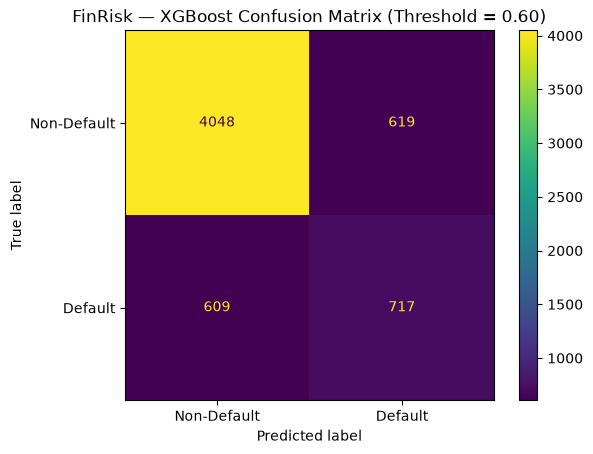

In [58]:
from sklearn.metrics import ConfusionMatrixDisplay

plt.figure(figsize=(7, 6))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    final_predictions,
    display_labels=["Non-Default", "Default"]
)

plt.title("FinRisk — XGBoost Confusion Matrix (Threshold = 0.60)")
plt.show()

In [59]:
customer = X_test.iloc[[0]]

customer_probability = best_model.predict_proba(
    customer
)[0, 1]

print(
    f"Predicted default probability: "
    f"{customer_probability:.2%}"
)

print(
    "Risk category:",
    risk_category(customer_probability)
)

Predicted default probability: 35.18%
Risk category: Medium Risk


In [60]:
customer.T

,8681
LIMIT_BAL,50000.000000
SEX,2.000000
EDUCATION,3.000000
MARRIAGE,1.000000
AGE,43.000000
PAY_0,0.000000
PAY_2,0.000000
PAY_3,0.000000
PAY_4,0.000000
PAY_5,0.000000


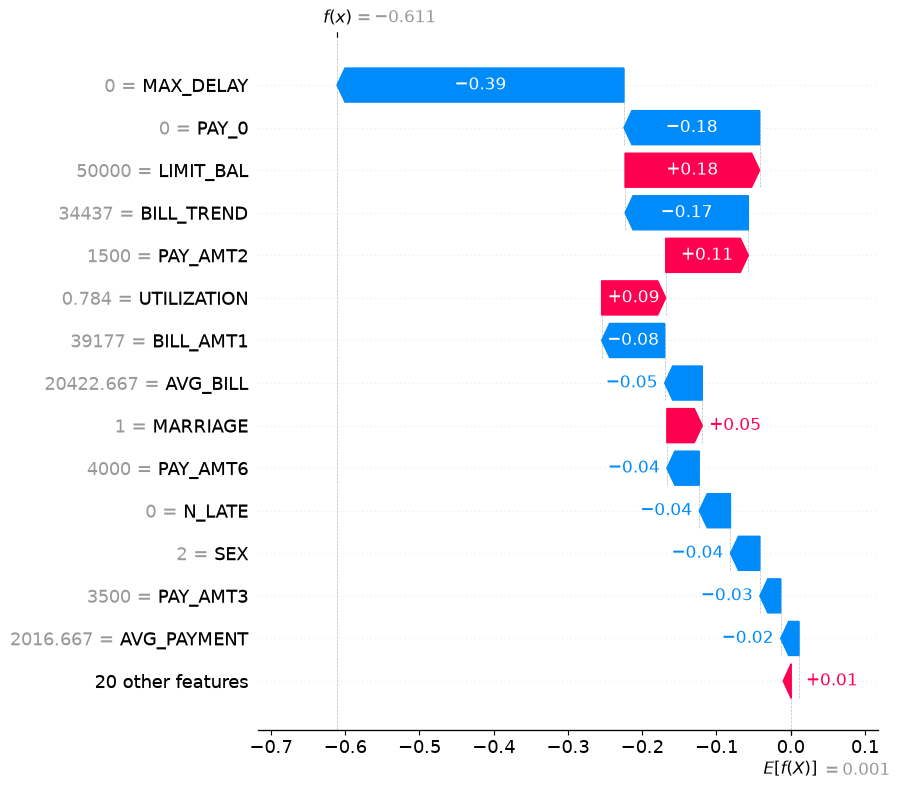

In [61]:
customer_shap = explainer(
    customer
)

shap.plots.waterfall(
    customer_shap[0],
    max_display=15
)

In [62]:
import sys

sys.path.append("../src")

from feature_engineering import (
    create_features,
    RAW_FEATURES
)

In [63]:
X_test_features = create_features(
    X_test[RAW_FEATURES]
)

print("Feature shape:", X_test_features.shape)
print("Feature count:", len(X_test_features.columns))

Feature shape: (5993, 34)
Feature count: 34


In [64]:
test_probabilities = best_model.predict_proba(
    X_test_features
)[:, 1]

print("First 10 probabilities:")
print(test_probabilities[:10])

First 10 probabilities:
[0.35180822 0.2115099  0.32406932 0.430428   0.07096709 0.16539282
 0.32737252 0.2596921  0.23039263 0.18748488]


In [65]:
import joblib

model_bundle = {
    "model": best_model,
    "feature_columns": X_train.columns.tolist(),
    "threshold": BEST_THRESHOLD,
    "risk_bands": {
        "low": 0.30,
        "medium": 0.60
    }
}

joblib.dump(
    model_bundle,
    "../models/finrisk_xgboost.pkl"
)

print("Model saved successfully.")

Model saved successfully.


In [66]:
loaded_bundle = joblib.load(
    "../models/finrisk_xgboost.pkl"
)

loaded_model = loaded_bundle["model"]

print(
    "Loaded model:",
    type(loaded_model).__name__
)

print(
    "Threshold:",
    loaded_bundle["threshold"]
)

print(
    "Number of features:",
    len(loaded_bundle["feature_columns"])
)

Loaded model: XGBClassifier
Threshold: 0.6
Number of features: 34


In [67]:
loaded_probability = loaded_model.predict_proba(
    X_test_features.iloc[[0]]
)[0, 1]

print(
    f"Loaded model probability: "
    f"{loaded_probability:.2%}"
)

Loaded model probability: 35.18%
